# Checador virtual con IA: modelo de predicción y regulación de rutas

**Proyecto final · Startup basada en Inteligencia Artificial**

Las rutas de transporte concesionado en México se regulan a mano: un checador anota a qué hora pasa cada unidad y avisa por voz o por WhatsApp cuánto le lleva la unidad de adelante. Solo hay información en los puntos donde hay checador, y las unidades terminan **amontonadas**: varias pasan juntas y después dejan huecos largos.

Este notebook construye y evalúa el núcleo de IA de la solución:

1. **Simulador de la ruta**, calibrado con tiempos aproximados definidos por la experiencia del equipo.
2. **Modelo de predicción de llegadas (ETA)**: cuántos minutos faltan para que una unidad llegue a cada parada. Se comparan dos técnicas: *gradient boosting* y una red neuronal (Keras).
3. **Modelo de detección temprana de amontonamiento**: predice si una unidad se va a pegar a la de adelante en las próximas 3 paradas.
4. **Regulación**: compara la operación sin control, con la regla del checador y con recomendaciones de la IA.
5. **Demostración** de lo que verían el pasajero, el conductor y el checador.

> **Sobre los datos.** No contamos con registros reales de una ruta. Todos los datos de este notebook se generan con un simulador cuyos tiempos se definieron por experiencia. Lo que se demuestra es que el sistema completo funciona y supera a métodos simples **dentro de la simulación**; la precisión real se validará con una ruta piloto.

## 1. Configuración

In [1]:
import os, json, time, heapq
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # oculta los avisos internos de TensorFlow (por ejemplo, sin GPU)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import joblib
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import mean_absolute_error, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import tensorflow as tf

SEMILLA = 42

# Paleta (validada para daltonismo) y estilo de gráficas
AZUL, NARANJA, AQUA, ROJO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b", "#b5b4ad"
TINTA, TINTA_2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 100, "font.size": 10,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA_2, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "legend.frameon": False,
})
pd.set_option("display.float_format", "{:.2f}".format)
hhmm = FuncFormatter(lambda m, _: f"{int(m // 60):02d}:{int(m % 60):02d}")

## 2. Definición de la ruta (tiempos por experiencia)

Usamos una **ruta ficticia** de 14 paradas. Los valores de esta sección son **supuestos del equipo**:

- **Minutos entre paradas** en horario normal.
- **Factor por hora**: cuánto más lento se circula en cada hora (1.40 = 40 % más lento en hora pico).
- **Intervalo programado**: cada cuántos minutos sale una unidad de la terminal.
- **Demanda**: pasajeros que llegan por minuto a una parada promedio; cada parada tiene un peso (las del centro, hospital y universidad atraen más gente).
- **Abordaje**: cada pasajero que sube o baja toma unos 6 segundos (pagar al chofer, cambio).
- **Flota**: 32 unidades de 22 pasajeros. Cada unidad hace la ida, regresa a la terminal y descansa 5 min antes de volver a salir. En hora pico hay hasta 30 unidades trabajando a la vez, así que con 32 nunca falta una para cumplir el horario.

In [2]:
PARADAS = ["Terminal Sur", "Mercado Municipal", "Av. Juárez", "Centro", "Catedral", "Hospital General",
           "Preparatoria 2", "Plaza Comercial", "Col. Las Flores", "Clínica IMSS", "Universidad",
           "Fracc. Real", "Glorieta Norte", "Terminal Norte"]
N_PARADAS = len(PARADAS)

TRAMO_MIN   = np.array([3.0, 2.5, 2.0, 2.5, 3.5, 4.0, 3.0, 4.5, 3.0, 3.5, 5.0, 3.0, 4.0])  # min entre paradas
TIEMPO_ACUM = np.concatenate([[0], np.cumsum(TRAMO_MIN)])
PESO_PARADA = np.array([2.0, 1.2, 1.0, 1.8, 1.0, 1.6, 1.2, 1.3, 0.8, 1.0, 1.5, 0.8, 0.6, 0.0])
PROB_BAJAR  = np.array([0, .05, .10, .25, .15, .25, .15, .20, .15, .20, .30, .25, .30, 1.0])

FACTOR_HORA    = {5: .85, 6: 1.0, 7: 1.35, 8: 1.40, 9: 1.10, 10: 1.0, 11: 1.0, 12: 1.05, 13: 1.20, 14: 1.25,
                  15: 1.10, 16: 1.05, 17: 1.15, 18: 1.35, 19: 1.30, 20: 1.05, 21: .90, 22: .85}
INTERVALO_PROG = {5: 10, 6: 8, 7: 6, 8: 6, 9: 8, 10: 8, 11: 8, 12: 8, 13: 7, 14: 7, 15: 8, 16: 8,
                  17: 7, 18: 6, 19: 6, 20: 8, 21: 10}
DEMANDA_HORA   = {5: .15, 6: .30, 7: .50, 8: .50, 9: .30, 10: .25, 11: .25, 12: .28, 13: .38, 14: .40,
                  15: .30, 16: .30, 17: .35, 18: .50, 19: .45, 20: .25, 21: .15, 22: .10}

CAPACIDAD, FLOTA = 22, 32
DESCANSO_MIN = 5          # minutos de descanso en la terminal entre una vuelta y la siguiente
PERMANENCIA_BASE, MIN_POR_PASAJERO = 0.25, 0.10      # minutos
PRIMERA_SALIDA, ULTIMA_SALIDA = 5 * 60 + 30, 21 * 60 + 30
UMBRAL_AMONTONADA = 0.35   # intervalo real < 35 % del programado = unidades amontonadas

def factor_hora(t):    return FACTOR_HORA.get(int(t // 60), 1.0)
def intervalo_prog(t): return INTERVALO_PROG.get(int(t // 60), 10)
def demanda(t):        return DEMANDA_HORA.get(int(t // 60), 0.1)

ruta = pd.DataFrame({"parada": PARADAS, "min_desde_anterior": np.r_[0, TRAMO_MIN],
                     "min_acumulados": TIEMPO_ACUM, "peso_demanda": PESO_PARADA})
display(ruta)
print(f"Recorrido completo: {TIEMPO_ACUM[-1]:.0f} min en horario normal y ~{TIEMPO_ACUM[-1] * 1.4:.0f} min en hora pico, sin contar paradas.")

,parada,min_desde_anterior,min_acumulados,peso_demanda
0,Terminal Sur,0.00,0.00,2.00
1,Mercado Municipal,3.00,3.00,1.20
2,Av. Juárez,2.50,5.50,1.00
3,Centro,2.00,7.50,1.80
4,Catedral,2.50,10.00,1.00
5,Hospital General,3.50,13.50,1.60
6,Preparatoria 2,4.00,17.50,1.20
7,Plaza Comercial,3.00,20.50,1.30
8,Col. Las Flores,4.50,25.00,0.80
9,Clínica IMSS,3.00,28.00,1.00


Recorrido completo: 44 min en horario normal y ~61 min en hora pico, sin contar paradas.


## 3. Simulador de la operación

Cada día salen unidades de la Terminal Sur según el intervalo programado. Para cada unidad y cada parada el simulador calcula:

- **Tiempo de tramo** = tiempo base × factor de la hora × tráfico del día × variación aleatoria, más incidentes ocasionales (1.5 % de los tramos, de 2 a 8 min).
- **Pasajeros que suben**: dependen de cuánto tiempo pasó desde la unidad anterior. Si una unidad va retrasada, encuentra más gente, tarda más en subirla y se retrasa todavía más; la de atrás encuentra la parada vacía y la alcanza. **Así nace el amontonamiento**, igual que en la calle.
- Las unidades no se rebasan.
- **Asignación de unidades**: cada salida la toma la unidad que lleva más tiempo libre en la terminal. El regreso no se simula parada por parada: se supone que dura lo mismo que la ida, más el descanso. Si ninguna unidad estuviera libre, la salida se retrasaría; la columna `demora_flota` lo registra.

En cada parada se registran las **variables que el sistema conocería en tiempo real** con el GPS de los celulares. La función `rasgos` se usa tanto para armar los datos de entrenamiento como dentro de la simulación cuando la IA toma decisiones, así que no se usa información del futuro.

In [3]:
RASGOS = ["parada", "hora", "fin_semana", "intervalo_prog", "intervalo_ant", "razon_intervalo",
          "cambio_intervalo", "retraso", "carga", "ultimo_tramo_razon"]

def rasgos(k, i, llegada, partida, salidas, carga_llegada, fin_semana):
    # Variables observables cuando la unidad k llega a la parada i
    t = llegada[k, i]
    prog = intervalo_prog(salidas[k])
    if k > 0:
        ant = t - llegada[k - 1, i]                                            # minutos detrás de la unidad de adelante
        ant_previo = (llegada[k, i - 1] - llegada[k - 1, i - 1]) if i > 0 else ant
    else:
        ant = ant_previo = prog
    return {"parada": i, "hora": t / 60, "fin_semana": int(fin_semana), "intervalo_prog": prog,
            "intervalo_ant": ant, "razon_intervalo": ant / prog, "cambio_intervalo": ant - ant_previo,
            "retraso": (t - salidas[k]) - TIEMPO_ACUM[i], "carga": carga_llegada[k, i],
            "ultimo_tramo_razon": (t - partida[k, i - 1]) / TRAMO_MIN[i - 1] if i > 0 else 1.0}


def programar_salidas():
    t, salidas = PRIMERA_SALIDA, []
    while t <= ULTIMA_SALIDA:
        salidas.append(t)
        t += intervalo_prog(t)
    return np.array(salidas, dtype=float)


def simular_dia(dia, politica=None):
    # politica(rasgos) -> minutos que la unidad debe retenerse en la parada (0 = seguir)
    rng = np.random.default_rng(SEMILLA * 1000 + dia)      # mismo día aleatorio para cualquier política
    fin_semana = dia % 7 in (5, 6)
    salidas = programar_salidas()
    n = len(salidas)
    trafico_dia = rng.lognormal(0, 0.07) * (0.88 if fin_semana else 1.0)
    trafico_hora = rng.lognormal(0, 0.06, 24)
    ruido_tramo = rng.lognormal(0, 0.12, (n, N_PARADAS - 1))
    incidente = np.where(rng.random((n, N_PARADAS - 1)) < 0.015, rng.uniform(2, 8, (n, N_PARADAS - 1)), 0.0)
    ruido_demanda = rng.gamma(4, 0.25, (n, N_PARADAS))
    ruido_salida = rng.normal(0, 1.0, n)
    factor_demanda = 0.75 if fin_semana else 1.0

    llegada = np.zeros((n, N_PARADAS)); partida = np.zeros_like(llegada); carga_llegada = np.zeros_like(llegada)
    libres = [(-np.inf, u) for u in range(1, FLOTA + 1)]     # (minuto en que queda libre, unidad)
    filas = []
    for k in range(n):
        libre_desde, unidad = heapq.heappop(libres)           # la unidad que lleva más tiempo libre
        salida_plan = salidas[k] + max(ruido_salida[k], -1.5)
        t = max(salida_plan, libre_desde)                     # si no hay unidad libre, la salida espera
        demora_flota = t - salida_plan
        ocupacion = 0.0
        for i in range(N_PARADAS):
            if i > 0:
                t += (TRAMO_MIN[i - 1] * factor_hora(t) * trafico_dia * trafico_hora[int(t // 60)]
                      * ruido_tramo[k, i - 1] + incidente[k, i - 1])
            if k > 0:
                t = max(t, llegada[k - 1, i] + 0.3)                          # no se rebasan
            llegada[k, i] = t
            carga_llegada[k, i] = ocupacion
            espera = t - partida[k - 1, i] if k > 0 else intervalo_prog(salidas[k])
            bajan = ocupacion * PROB_BAJAR[i]
            ocupacion -= bajan
            quieren = demanda(t) * factor_demanda * PESO_PARADA[i] * max(espera, 0) * ruido_demanda[k, i]
            suben = min(quieren, CAPACIDAD - ocupacion)
            ocupacion += suben
            r = rasgos(k, i, llegada, partida, salidas, carga_llegada, fin_semana)
            retencion = politica(r) if politica is not None else 0.0
            partida[k, i] = t + PERMANENCIA_BASE + MIN_POR_PASAJERO * (suben + bajan) + retencion
            t = partida[k, i]
            filas.append({"dia": dia, "viaje": k, "unidad": unidad, "salida_prog": salidas[k], **r,
                          "llegada": llegada[k, i], "partida": partida[k, i],
                          "suben": suben, "bajan": bajan, "retencion": retencion, "demora_flota": demora_flota})
        # Regreso a la terminal: se supone igual de largo que la ida, más el descanso
        ida = t - llegada[k, 0]
        heapq.heappush(libres, (t + ida + DESCANSO_MIN, unidad))
    return pd.DataFrame(filas)

Simulamos **6 semanas (42 días)**. Las primeras 34 se usan para entrenar y las últimas 8 se reservan como prueba: el modelo nunca las ve.

In [4]:
N_DIAS, DIAS_ENTRENAMIENTO = 42, 34
t0 = time.time()
datos = pd.concat([simular_dia(d) for d in range(N_DIAS)], ignore_index=True)
datos["amontonada"] = (datos.viaje > 0) & (datos.razon_intervalo < UMBRAL_AMONTONADA)
print(f"{len(datos):,} registros de llegada · {datos.groupby('dia').viaje.nunique().mean():.0f} viajes por día "
      f"· {N_DIAS} días · {time.time() - t0:.1f} s")
salidas_dia = datos[datos.parada == 0]
print(f"Flota de {FLOTA} unidades · {salidas_dia.groupby(['dia', 'unidad']).size().mean():.1f} vueltas por unidad al día "
      f"· salidas retrasadas por falta de unidad: {(salidas_dia.demora_flota > 0).sum()}")
display(datos[["dia", "viaje", "unidad", "parada", "hora", "intervalo_ant", "razon_intervalo",
               "retraso", "carga", "suben"]].head(8))

77,616 registros de llegada · 132 viajes por día · 42 días · 0.7 s
Flota de 32 unidades · 4.1 vueltas por unidad al día · salidas retrasadas por falta de unidad: 0


,dia,viaje,unidad,parada,hora,intervalo_ant,razon_intervalo,retraso,carga,suben
0,0,0,1,0,5.52,10.00,1.00,1.02,0.00,2.89
1,0,0,1,1,5.57,10.00,1.00,0.95,2.89,2.08
2,0,0,1,2,5.61,10.00,1.00,1.02,4.82,0.67
3,0,0,1,3,5.64,10.00,1.00,0.99,5.01,2.67
4,0,0,1,4,5.68,10.00,1.00,0.99,6.42,1.91
5,0,0,1,5,5.73,10.00,1.00,0.49,7.37,1.33
6,0,0,1,6,5.79,10.00,1.00,-0.06,6.86,2.45
7,0,0,1,7,5.84,10.00,1.00,0.11,8.28,2.39


### 3.1 ¿Cuándo se amontonan las unidades?

Contamos una llegada como **amontonada** cuando la unidad pasa a menos del 35 % del intervalo programado detrás de la de adelante (por ejemplo, a menos de 2.1 min cuando deberían ir cada 6).

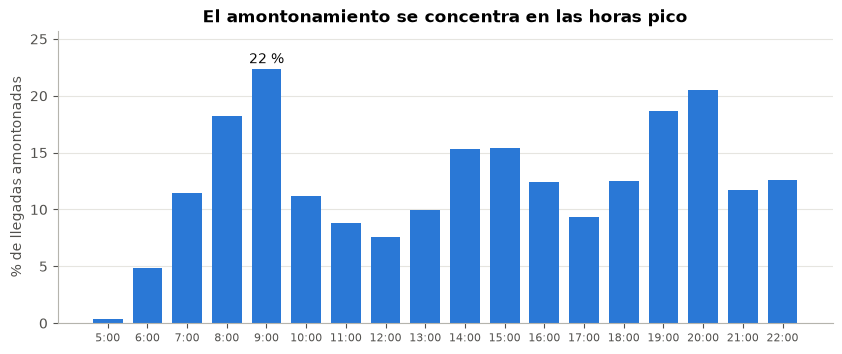

Promedio del día: 13.7 % de las llegadas van amontonadas.


In [5]:
d = datos[datos.viaje > 0].copy()
d["h"] = d.hora.astype(int)
por_hora = d.groupby("h").amontonada.mean() * 100

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(por_hora.index, por_hora.values, color=AZUL, width=0.75)
ax.set_xticks(por_hora.index, [f"{h}:00" for h in por_hora.index], rotation=0, fontsize=8)
ax.set_ylabel("% de llegadas amontonadas")
ax.set_title("El amontonamiento se concentra en las horas pico")
ax.set_ylim(0, por_hora.max() * 1.15)
top = por_hora.idxmax()
ax.annotate(f"{por_hora.max():.0f} %", (top, por_hora.max()), xytext=(0, 4), textcoords="offset points",
            ha="center", color=TINTA)
ax.grid(axis="x", visible=False)
plt.show()
print(f"Promedio del día: {d.amontonada.mean() * 100:.1f} % de las llegadas van amontonadas.")

### 3.2 Diagrama espacio-tiempo de una mañana

Cada línea es una unidad recorriendo la ruta (eje vertical) a lo largo del tiempo (eje horizontal). Cuando dos líneas se juntan, las unidades van pegadas; los puntos rojos marcan esas llegadas. Esto es justo lo que el checador intenta evitar desde un solo punto de la ruta.

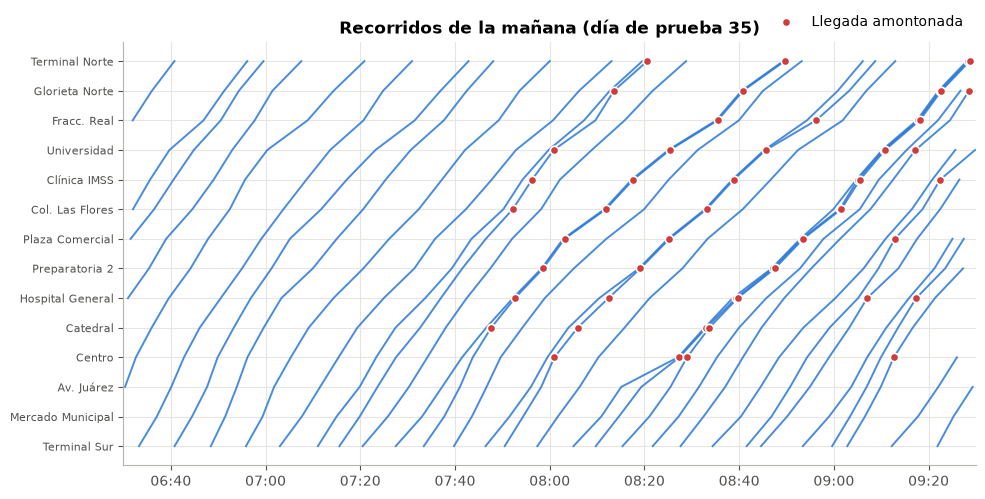

In [6]:
DIA_DEMO = DIAS_ENTRENAMIENTO + 1            # un lunes del periodo de prueba
dd = datos[(datos.dia == DIA_DEMO) & (datos.llegada.between(6.5 * 60, 9.5 * 60))]

fig, ax = plt.subplots(figsize=(11, 5.5))
for _, g in dd.groupby("viaje"):
    ax.plot(g.llegada, g.parada, color=AZUL, lw=1.4, alpha=0.85)
m = dd[dd.amontonada]
ax.scatter(m.llegada, m.parada, s=36, color=ROJO, zorder=3, edgecolor="white", linewidth=1.2,
           label="Llegada amontonada")
ax.set_yticks(range(N_PARADAS), PARADAS, fontsize=8)
ax.xaxis.set_major_formatter(hhmm)
ax.set_xlim(6.5 * 60, 9.5 * 60)
ax.set_title(f"Recorridos de la mañana (día de prueba {DIA_DEMO})")
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0))
plt.show()

## 4. Modelo 1: predicción de tiempo de llegada (ETA)

**Pregunta:** si una unidad acaba de llegar a la parada *i*, ¿en cuántos minutos llegará a la parada *j*?

Cada llegada genera un ejemplo por cada parada que le falta. Comparamos dos métodos sin IA y dos técnicas de IA:

| Método | Cómo calcula | Equivale a |
|---|---|---|
| Tiempo base | Suma de los minutos por experiencia | Lo que diría el checador |
| Promedio histórico | Promedio de cada tramo a esa hora, con datos de entrenamiento | Una app de GPS sencilla |
| **Modelo IA** | Gradient boosting con el estado en tiempo real | Nuestra solución |
| Red neuronal | Perceptrón multicapa (Keras) con las mismas variables (sección 4.3) | Lo visto en clase |

In [7]:
def armar_eta(df):
    df = df.sort_values(["dia", "viaje", "parada"])
    cols = ["dia", "viaje", "unidad"] + RASGOS + ["llegada"]
    por_parada = {i: df[df.parada == i][cols].reset_index(drop=True) for i in range(N_PARADAS)}
    partes = []
    for i in range(N_PARADAS - 1):
        for j in range(i + 1, N_PARADAS):
            p = por_parada[i].copy()
            p["destino"], p["n_tramos"] = j, j - i
            p["tiempo_base"] = TIEMPO_ACUM[j] - TIEMPO_ACUM[i]
            p["minutos_reales"] = por_parada[j].llegada.values - p.llegada.values
            partes.append(p)
    return pd.concat(partes, ignore_index=True)

eta = armar_eta(datos)
entrena = eta[eta.dia < DIAS_ENTRENAMIENTO].copy()
prueba = eta[eta.dia >= DIAS_ENTRENAMIENTO].copy()
DIAS_VALIDACION = 6   # últimos días de entrenamiento: validación de la red y del umbral de alerta

# Línea base 2: promedio histórico de cada tramo (incluye la parada) por hora del día
tr = datos[datos.dia < DIAS_ENTRENAMIENTO].sort_values(["dia", "viaje", "parada"]).copy()
tr["dur"] = tr.groupby(["dia", "viaje"]).llegada.shift(-1) - tr.llegada
tr["h"] = tr.hora.astype(int)
tabla = tr.dropna(subset=["dur"]).groupby(["h", "parada"]).dur.mean().unstack()
tabla = tabla.reindex(range(24)).fillna(tabla.mean())
ACUM_HIST = np.concatenate([np.zeros((24, 1)), np.cumsum(tabla.values, axis=1)], axis=1)

def base_historica(df):
    h = df.hora.astype(int).clip(0, 23).values
    return ACUM_HIST[h, df.destino.values] - ACUM_HIST[h, df.parada.values]

for x in (entrena, prueba):
    x["base_historica"] = base_historica(x)

X_ETA = RASGOS + ["destino", "n_tramos", "tiempo_base", "base_historica"]
print(f"Ejemplos de entrenamiento: {len(entrena):,} · de prueba: {len(prueba):,}")

Ejemplos de entrenamiento: 408,408 · de prueba: 96,096


In [8]:
t0 = time.time()
modelo_eta = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.08, max_leaf_nodes=48,
                                           l2_regularization=1.0, random_state=SEMILLA)
modelo_eta.fit(entrena[X_ETA], entrena.minutos_reales)
prueba["pred_ia"] = modelo_eta.predict(prueba[X_ETA])
print(f"Entrenado en {time.time() - t0:.1f} s")

def resumen(nombre, pred):
    err = (pred - prueba.minutos_reales).abs()
    return {"Método": nombre, "Error medio (min)": err.mean(), "Error p90 (min)": err.quantile(0.9),
            "% dentro de ±2 min": (err <= 2).mean() * 100}

res_eta = pd.DataFrame([resumen("Tiempo base (experiencia)", prueba.tiempo_base),
                        resumen("Promedio histórico", prueba.base_historica),
                        resumen("Modelo IA", prueba.pred_ia)]).set_index("Método")
display(res_eta)
mejora = 1 - res_eta.loc["Modelo IA", "Error medio (min)"] / res_eta.loc["Promedio histórico", "Error medio (min)"]
print(f"El modelo reduce el error medio {mejora * 100:.0f} % frente al promedio histórico.")

Entrenado en 5.8 s


,Error medio (min),Error p90 (min),% dentro de ±2 min
Método,,,
Tiempo base (experiencia),5.89,13.91,29.67
Promedio histórico,2.47,6.13,59.27
Modelo IA,1.84,4.41,68.16


El modelo reduce el error medio 26 % frente al promedio histórico.


### 4.1 Error según qué tan lejos está la parada

Predecir la siguiente parada es fácil; lo difícil es anticipar 8 o 10 paradas adelante, donde se acumulan el tráfico y el amontonamiento.

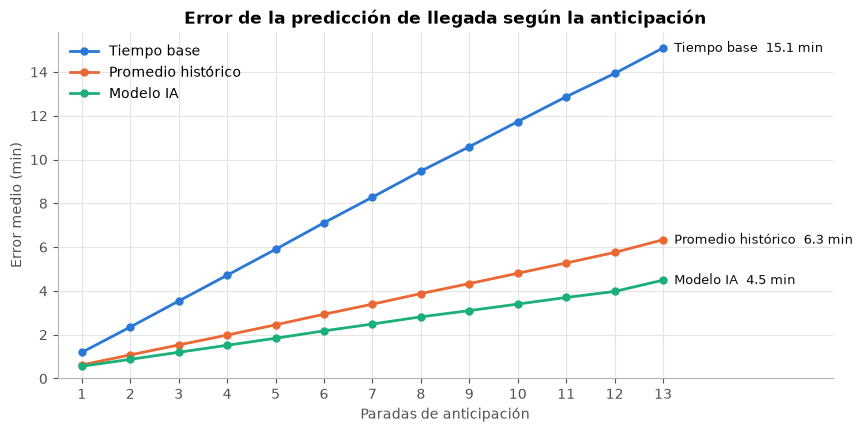

In [9]:
por_h = prueba.assign(e_base=(prueba.tiempo_base - prueba.minutos_reales).abs(),
                      e_hist=(prueba.base_historica - prueba.minutos_reales).abs(),
                      e_ia=(prueba.pred_ia - prueba.minutos_reales).abs()).groupby("n_tramos")[["e_base", "e_hist", "e_ia"]].mean()

fig, ax = plt.subplots(figsize=(10, 4.5))
for col, nombre, color in [("e_base", "Tiempo base", AZUL), ("e_hist", "Promedio histórico", NARANJA),
                           ("e_ia", "Modelo IA", AQUA)]:
    ax.plot(por_h.index, por_h[col], color=color, lw=2, marker="o", ms=5, label=nombre)
    ax.annotate(f"{nombre}  {por_h[col].iloc[-1]:.1f} min", (por_h.index[-1], por_h[col].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", color=TINTA, fontsize=9)
ax.set_xlabel("Paradas de anticipación")
ax.set_ylabel("Error medio (min)")
ax.set_xticks(por_h.index)
ax.set_xlim(0.5, 16.5)
ax.set_ylim(0, None)
ax.set_title("Error de la predicción de llegada según la anticipación")
ax.legend(loc="upper left")
plt.show()

### 4.2 ¿Qué está usando el modelo?

Importancia por permutación: cuánto empeora el error si se revuelve cada variable. El modelo parte del promedio histórico y lo corrige con lo que está pasando en ese momento: la hora, la velocidad del último tramo y el retraso acumulado. Esa corrección es la que baja el error de 2.5 a 1.8 min.

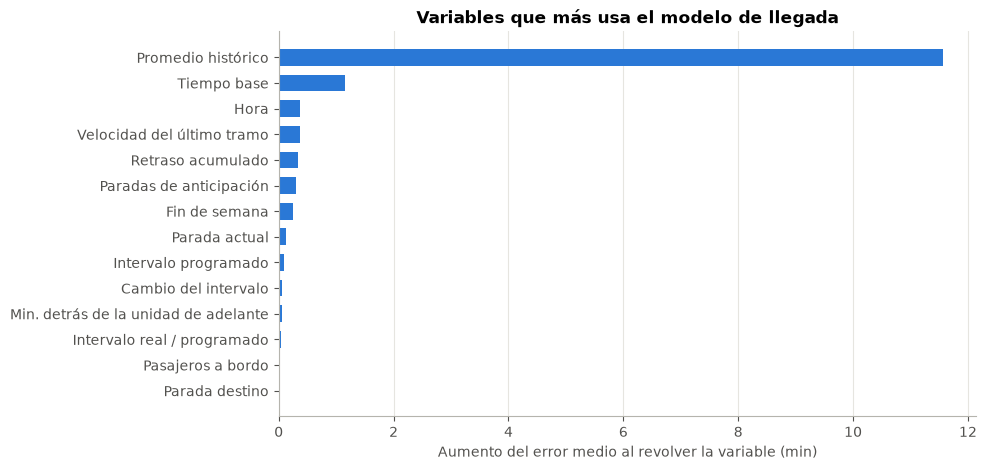

In [10]:
muestra = prueba.sample(20000, random_state=SEMILLA)
imp = permutation_importance(modelo_eta, muestra[X_ETA], muestra.minutos_reales, n_repeats=3,
                             random_state=SEMILLA, scoring="neg_mean_absolute_error")
imp = pd.Series(imp.importances_mean, index=X_ETA).sort_values()
NOMBRES = {"parada": "Parada actual", "hora": "Hora", "fin_semana": "Fin de semana",
           "intervalo_prog": "Intervalo programado", "intervalo_ant": "Min. detrás de la unidad de adelante",
           "razon_intervalo": "Intervalo real / programado", "cambio_intervalo": "Cambio del intervalo",
           "retraso": "Retraso acumulado", "carga": "Pasajeros a bordo", "ultimo_tramo_razon": "Velocidad del último tramo",
           "destino": "Parada destino", "n_tramos": "Paradas de anticipación", "tiempo_base": "Tiempo base",
           "base_historica": "Promedio histórico"}

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([NOMBRES[c] for c in imp.index], imp.values, color=AZUL, height=0.65)
ax.set_xlabel("Aumento del error medio al revolver la variable (min)")
ax.set_title("Variables que más usa el modelo de llegada")
ax.grid(axis="y", visible=False)
plt.show()

### 4.3 Comparación con una red neuronal (Keras)

Entrenamos también un **perceptrón multicapa**, como en las clases de redes neuronales, con las mismas variables y los mismos días.

- **Preparación:** la parada y el destino se codifican con *one-hot* (`OneHotEncoder`) y el resto de las variables se estandariza (`StandardScaler`).
- **Arquitectura:** dos capas ocultas (64 y 32 neuronas, ReLU) y una salida lineal: los minutos que faltan.
- **Entrenamiento:** se minimiza el error medio absoluto con Adam. Los últimos 6 días de entrenamiento se separan como validación para `EarlyStopping`, que detiene el entrenamiento cuando el error de validación deja de bajar y conserva los mejores pesos.

In [11]:
CATEGORICAS = ["parada", "destino"]
NUMERICAS = [c for c in X_ETA if c not in CATEGORICAS]
ent_red = entrena[entrena.dia < DIAS_ENTRENAMIENTO - DIAS_VALIDACION]
val_red = entrena[entrena.dia >= DIAS_ENTRENAMIENTO - DIAS_VALIDACION]

preparador = ColumnTransformer([
    ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAS),
    ("escala", StandardScaler(), NUMERICAS),
])
X_ent = preparador.fit_transform(ent_red[X_ETA]).astype("float32")
X_val = preparador.transform(val_red[X_ETA]).astype("float32")
X_pru = preparador.transform(prueba[X_ETA]).astype("float32")

tf.keras.utils.set_random_seed(SEMILLA)
red_eta = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_ent.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1),
])
red_eta.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="mae")
parada_temprana = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

t0 = time.time()
historia = red_eta.fit(X_ent, ent_red.minutos_reales.values,
                       validation_data=(X_val, val_red.minutos_reales.values),
                       epochs=100, batch_size=1024, callbacks=[parada_temprana], verbose=0)
print(f"Entrenada en {time.time() - t0:.0f} s · {len(historia.history['loss'])} épocas · "
      f"{red_eta.count_params():,} parámetros")
prueba["pred_red"] = red_eta.predict(X_pru, batch_size=4096, verbose=0).ravel()

Entrenada en 133 s · 99 épocas · 4,609 parámetros


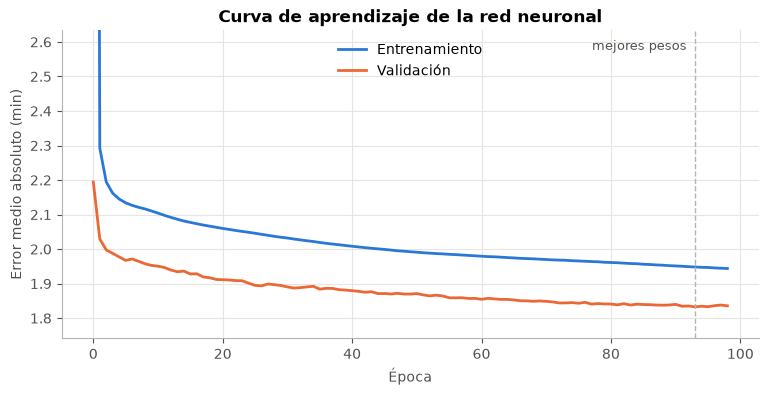

,Error medio (min),Error p90 (min),% dentro de ±2 min
Método,,,
Tiempo base (experiencia),5.89,13.91,29.67
Promedio histórico,2.47,6.13,59.27
Modelo IA,1.84,4.41,68.16
Red neuronal (Keras),1.85,4.54,68.71


In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(historia.history["loss"], color=AZUL, lw=2, label="Entrenamiento")
ax.plot(historia.history["val_loss"], color=NARANJA, lw=2, label="Validación")
mejor = int(np.argmin(historia.history["val_loss"]))
# La primera época (error de ~8 min) se deja fuera de la escala para ver el detalle
ax.set_ylim(min(historia.history["val_loss"]) * 0.95, historia.history["val_loss"][0] * 1.2)
ax.axvline(mejor, color=GRIS, ls="--", lw=1)
ax.annotate("mejores pesos", (mejor, ax.get_ylim()[1]), xytext=(-6, -14), textcoords="offset points",
            ha="right", color=TINTA_2, fontsize=9)
ax.set_xlabel("Época")
ax.set_ylabel("Error medio absoluto (min)")
ax.set_title("Curva de aprendizaje de la red neuronal")
ax.legend(loc="upper center")
plt.show()

fila = resumen("Red neuronal (Keras)", prueba.pred_red)
res_eta.loc[fila.pop("Método")] = fila
display(res_eta)

**Lectura.** La red neuronal llega prácticamente al mismo error que el gradient boosting (1.85 contra 1.84 min; 68.7 % contra 68.2 % de predicciones dentro de ±2 min).

- Las dos técnicas aprenden lo mismo: la mejora frente al promedio histórico (2.47 min) viene de usar el **estado en tiempo real** de la ruta, no de una técnica en particular.
- La curva no muestra sobreajuste: el error de validación baja junto con el de entrenamiento y se estabiliza.
- Para el producto se queda el **gradient boosting**: entrena en segundos (la red tarda unos 2 min), no necesita preparar las variables y permite ver qué variables usa (sección 4.2). La red se exporta como alternativa.

## 5. Modelo 2: detección temprana de amontonamiento

**Pregunta:** cuando una unidad llega a la parada *i*, ¿estará amontonada con la de adelante **3 paradas después**?

Si se detecta a tiempo, basta con pedirle al conductor que baje un poco el ritmo. Lo comparamos con la **regla del checador**: avisar solo cuando la unidad *ya* va a menos del 60 % del intervalo programado.

Para elegir el umbral de alerta separamos los últimos 6 días de entrenamiento como validación.

In [13]:
cl = datos.sort_values(["dia", "viaje", "parada"]).copy()
cl["amontonada_en_3"] = cl.groupby(["dia", "viaje"]).amontonada.shift(-3)
cl = cl[(cl.viaje > 0) & cl.amontonada_en_3.notna()].copy()
cl["amontonada_en_3"] = cl.amontonada_en_3.astype(int)

ent_c = cl[cl.dia < DIAS_ENTRENAMIENTO - DIAS_VALIDACION]
val_c = cl[(cl.dia >= DIAS_ENTRENAMIENTO - DIAS_VALIDACION) & (cl.dia < DIAS_ENTRENAMIENTO)]
pru_c = cl[cl.dia >= DIAS_ENTRENAMIENTO]
print(f"Casos positivos en entrenamiento: {ent_c.amontonada_en_3.mean() * 100:.1f} %")

clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06, max_leaf_nodes=31,
                                     l2_regularization=1.0, random_state=SEMILLA)
clf.fit(ent_c[RASGOS].values, ent_c.amontonada_en_3)

# Umbral que maximiza F1 en validación
p_val = clf.predict_proba(val_c[RASGOS].values)[:, 1]
umbrales = np.arange(0.15, 0.75, 0.025)
UMBRAL_ALERTA = float(umbrales[np.argmax([f1_score(val_c.amontonada_en_3, p_val >= u) for u in umbrales])])
print(f"Umbral de alerta elegido en validación: {UMBRAL_ALERTA:.3f}")

y = pru_c.amontonada_en_3
p_pru = clf.predict_proba(pru_c[RASGOS].values)[:, 1]
reglas = {"Regla del checador (ya va a < 60 %)": (pru_c.razon_intervalo < 0.6).astype(int),
          "Modelo IA": (p_pru >= UMBRAL_ALERTA).astype(int)}
res_clf = pd.DataFrame([{"Método": n, "Precisión": precision_score(y, a), "Exhaustividad (recall)": recall_score(y, a),
                         "F1": f1_score(y, a)} for n, a in reglas.items()]).set_index("Método")
display(res_clf)
print(f"AUC del modelo IA en prueba: {roc_auc_score(y, p_pru):.3f}")

# Casos difíciles: la unidad todavía NO va pegada (intervalo >= 60 %), pero se pegará en 3 paradas
nuevos = (pru_c.razon_intervalo >= 0.6).values
alerta_ia = p_pru >= UMBRAL_ALERTA
print(f"Casos que empiezan sin señal (la unidad todavía va a >= 60 % del intervalo): {y[nuevos].sum()}. "
      f"La regla no detecta ninguno; el modelo detecta {recall_score(y[nuevos], alerta_ia[nuevos]) * 100:.0f} % "
      f"con precisión de {precision_score(y[nuevos], alerta_ia[nuevos]) * 100:.0f} %.")
print("Precisión = de las alertas, cuántas eran reales. Exhaustividad = de los amontonamientos reales, cuántos se anticiparon.")

Casos positivos en entrenamiento: 17.4 %


Umbral de alerta elegido en validación: 0.375


,Precisión,Exhaustividad (recall),F1
Método,,,
Regla del checador (ya va a < 60 %),0.75,0.81,0.78
Modelo IA,0.80,0.78,0.79


AUC del modelo IA en prueba: 0.952
Casos que empiezan sin señal (la unidad todavía va a >= 60 % del intervalo): 351. La regla no detecta ninguno; el modelo detecta 6 % con precisión de 34 %.
Precisión = de las alertas, cuántas eran reales. Exhaustividad = de los amontonamientos reales, cuántos se anticiparon.


### 5.1 Matrices de confusión

Cómo se reparten los aciertos y errores de cada método en los días de prueba. Los falsos positivos son avisos innecesarios al conductor; los falsos negativos, amontonamientos que no se anticiparon.

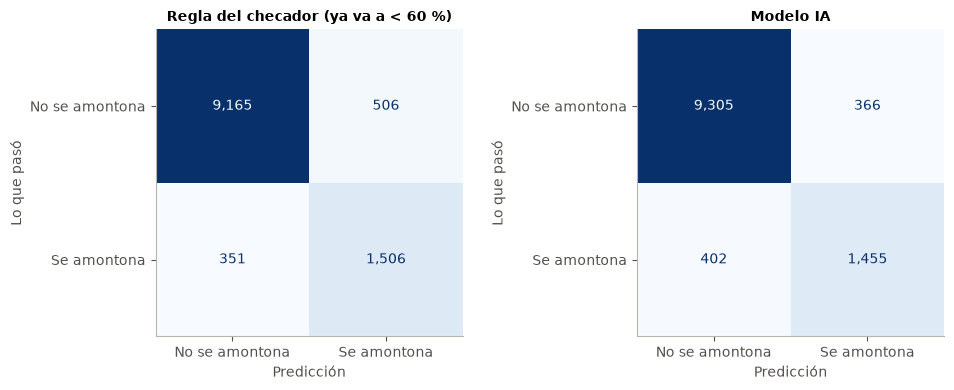

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nombre, alerta) in zip(axes, reglas.items()):
    ConfusionMatrixDisplay.from_predictions(y, alerta, display_labels=["No se amontona", "Se amontona"],
                                            cmap="Blues", colorbar=False, ax=ax, values_format=",")
    ax.set_title(nombre, fontsize=10)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Lo que pasó")
    ax.grid(False)
plt.tight_layout()
plt.show()

**Lectura.** El modelo da **28 % menos avisos innecesarios** que la regla (366 contra 506), a cambio de dejar pasar algunos amontonamientos más (402 contra 351). Para el conductor eso importa: si recibe demasiados avisos falsos, deja de hacerles caso.

## 6. Regulación: ¿sirve de algo avisar?

Simulamos de nuevo los 8 días de prueba **con exactamente el mismo tráfico, incidentes y pasajeros**, cambiando solo la forma de regular:

| Escenario | Dónde actúa | Cuándo actúa | Qué hace |
|---|---|---|---|
| Sin control | — | — | Cada unidad sigue a su ritmo |
| Checador | 3 puntos fijos (Centro, Plaza Comercial, Universidad) | Cuando la unidad **ya** va pegada | La detiene hasta recuperar el 80 % del intervalo, máximo 3 min |
| Regla en todas las paradas | Cualquier parada, vía mensaje al conductor | Cuando la unidad **ya** va pegada | Le pide bajar el ritmo entre 0.5 y 2 min |
| IA | Cualquier parada, vía mensaje al conductor | Cuando el modelo **predice** que se va a pegar | Le pide bajar el ritmo entre 0.5 y 2 min |

El tercer escenario es un **control experimental**: usa la plataforma (rastreo en todas las paradas y aviso al conductor) pero sin modelo. Sirve para separar cuánto aporta la plataforma y cuánto aporta la predicción.

In [15]:
PUNTOS_CHECADOR = {3, 7, 10}

def politica_checador(r):
    if r["parada"] in PUNTOS_CHECADOR and r["razon_intervalo"] < 0.6:
        return float(min(3.0, 0.8 * r["intervalo_prog"] - r["intervalo_ant"]))
    return 0.0

def politica_ia(r):
    if 1 <= r["parada"] <= N_PARADAS - 4:
        p = clf.predict_proba(np.array([[r[c] for c in RASGOS]]))[0, 1]
        if p >= UMBRAL_ALERTA:
            return float(np.clip(0.8 * r["intervalo_prog"] - r["intervalo_ant"], 0.5, 2.0))
    return 0.0

def politica_regla_app(r):
    # Misma acción que la IA y en las mismas paradas, pero disparada por la regla del checador
    if 1 <= r["parada"] <= N_PARADAS - 4 and r["razon_intervalo"] < 0.6:
        return float(np.clip(0.8 * r["intervalo_prog"] - r["intervalo_ant"], 0.5, 2.0))
    return 0.0

def metricas(df):
    d = df[df.viaje > 0]
    h = d.intervalo_ant
    por_vuelta = df.groupby(["dia", "viaje"]).suben.sum()
    ini = df[df.parada == 0].set_index(["dia", "viaje"]).llegada
    fin = df[df.parada == N_PARADAS - 1].set_index(["dia", "viaje"]).llegada
    return {"% llegadas amontonadas": (d.razon_intervalo < UMBRAL_AMONTONADA).mean() * 100,
            "Espera promedio del pasajero (min)": (h ** 2).sum() / (2 * h.sum()),
            "Pasajeros por vuelta": por_vuelta.mean(),
            "Desigualdad entre vueltas (desv. est. pasajeros)": por_vuelta.std(),
            "Tiempo de recorrido (min)": (fin - ini).mean(),
            "Avisos o retenciones por vuelta": (df.retencion > 0).groupby([df.dia, df.viaje]).sum().mean()}

t0 = time.time()
DIAS_PRUEBA = range(DIAS_ENTRENAMIENTO, N_DIAS)
escenarios = {"Sin control": None, "Checador": politica_checador, "Regla en todas las paradas": politica_regla_app,
              "IA": politica_ia}
sims = {n: pd.concat([simular_dia(d, p) for d in DIAS_PRUEBA], ignore_index=True) for n, p in escenarios.items()}
res_ctrl = pd.DataFrame({n: metricas(s) for n, s in sims.items()})
display(res_ctrl)
print(f"Simulación de escenarios: {time.time() - t0:.0f} s")

,Sin control,Checador,Regla en todas las paradas,IA
% llegadas amontonadas,12.90,6.24,3.08,3.35
Espera promedio del pasajero (min),4.75,4.46,4.33,4.37
Pasajeros por vuelta,30.98,30.48,30.49,30.50
Desigualdad entre vueltas (desv. est. pasajeros),15.87,14.15,13.13,13.34
Tiempo de recorrido (min),58.43,59.21,59.63,59.51
Avisos o retenciones por vuelta,0.00,0.58,1.12,1.10


Simulación de escenarios: 34 s


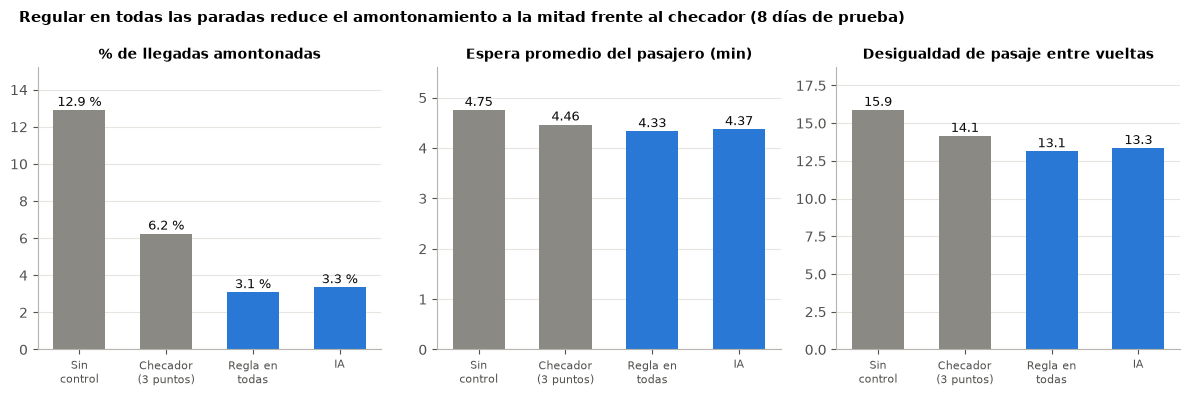

In [16]:
# Operación actual en gris; las dos opciones que usan la plataforma en azul
cols = {"Sin control": "#8a8984", "Checador": "#8a8984", "Regla en todas las paradas": AZUL, "IA": AZUL}
etiquetas = {"Sin control": "Sin\ncontrol", "Checador": "Checador\n(3 puntos)",
             "Regla en todas las paradas": "Regla en\ntodas", "IA": "IA"}
indicadores = [("% llegadas amontonadas", "% de llegadas amontonadas", "{:.1f} %"),
               ("Espera promedio del pasajero (min)", "Espera promedio del pasajero (min)", "{:.2f}"),
               ("Desigualdad entre vueltas (desv. est. pasajeros)", "Desigualdad de pasaje entre vueltas", "{:.1f}")]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (fila, titulo, fmt) in zip(axes, indicadores):
    vals = res_ctrl.loc[fila]
    ax.bar([etiquetas[n] for n in vals.index], vals.values, color=[cols[n] for n in vals.index], width=0.6)
    ax.tick_params(axis="x", labelsize=8)
    for x, v in enumerate(vals.values):
        ax.annotate(fmt.format(v), (x, v), xytext=(0, 3), textcoords="offset points", ha="center", color=TINTA, fontsize=9)
    ax.set_title(titulo, fontsize=10)
    ax.set_ylim(0, vals.max() * 1.18)
    ax.grid(axis="x", visible=False)
fig.suptitle("Regular en todas las paradas reduce el amontonamiento a la mitad frente al checador (8 días de prueba)",
             fontweight="bold", x=0.02, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

## 7. Demostración: lo que ve cada usuario

Tomamos el día de prueba a las **7:45 a.m.** (con regulación de la IA) y generamos lo que recibiría cada tipo de usuario. En el plan B, estas mismas funciones alimentan la app interactiva y la API.

In [17]:
def estado_en(df_dia, t):
    # Última parada alcanzada por cada unidad que está en ruta en el minuto t
    vistos = df_dia[df_dia.llegada <= t].sort_values(["viaje", "parada"]).groupby("viaje").tail(1)
    return vistos[vistos.parada < N_PARADAS - 1]

def fila_eta(fila, destino):
    x = fila[RASGOS].to_frame().T.astype(float)
    x["destino"], x["n_tramos"] = destino, destino - fila.parada
    x["tiempo_base"] = TIEMPO_ACUM[destino] - TIEMPO_ACUM[int(fila.parada)]
    x["destino"] = x["destino"].astype(int); x["parada"] = x["parada"].astype(int)
    x["base_historica"] = base_historica(x)
    return x[X_ETA]

def consulta_pasajero(df_dia, nombre_parada, t, n=3):
    destino = PARADAS.index(nombre_parada)
    vienen = estado_en(df_dia, t)
    vienen = vienen[vienen.parada < destino]
    filas = []
    for _, f in vienen.iterrows():
        minutos = float(modelo_eta.predict(fila_eta(f, destino))[0]) - (t - f.llegada)
        real = df_dia[(df_dia.viaje == f.viaje) & (df_dia.parada == destino)].llegada.iloc[0] - t
        filas.append({"Unidad": int(f.unidad), "Ahora en": PARADAS[int(f.parada)],
                      "Llega en (predicción)": max(minutos, 0.5), "Llegó en (simulación)": real})
    return pd.DataFrame(filas).sort_values("Llega en (predicción)").head(n).reset_index(drop=True)

def mensaje_conductor(fila):
    p = clf.predict_proba(np.array([[fila[c] for c in RASGOS]]))[0, 1]
    unidad, parada, ant = int(fila.unidad), PARADAS[int(fila.parada)], fila.intervalo_ant
    if fila.viaje == 0:
        return f"Unidad {unidad}: eres la primera del día, mantén el ritmo normal."
    if p >= UMBRAL_ALERTA:
        espera = np.clip(0.8 * fila.intervalo_prog - ant, 0.5, 2.0)
        return (f"Unidad {unidad}: vas {ant:.1f} min detrás de la de adelante y te estás pegando "
                f"(riesgo {p:.0%}). Baja el ritmo ~{espera:.1f} min después de {parada}.")
    if fila.razon_intervalo > 1.5:
        return f"Unidad {unidad}: hay un hueco de {ant:.0f} min adelante. Mantén el ritmo y no te detengas de más."
    return f"Unidad {unidad}: vas bien, {ant:.1f} min detrás de la de adelante."

dia_ia = sims["IA"][sims["IA"].dia == DIA_DEMO]
T_DEMO = 7 * 60 + 45

print("PASAJERO · consulta web: «¿Cuándo pasa la siguiente unidad por Hospital General?»")
display(consulta_pasajero(dia_ia, "Hospital General", T_DEMO))

print("\nCONDUCTORES · mensajes de Telegram a las 07:45")
for _, f in estado_en(dia_ia, T_DEMO).sort_values("parada", ascending=False).iterrows():
    print("  •", mensaje_conductor(f))

PASAJERO · consulta web: «¿Cuándo pasa la siguiente unidad por Hospital General?»


,Unidad,Ahora en,Llega en (predicción),Llegó en (simulación)
0,16,Centro,7.86,7.25
1,17,Centro,8.32,11.47
2,18,Mercado Municipal,14.96,13.57



CONDUCTORES · mensajes de Telegram a las 07:45
  • Unidad 10: vas bien, 5.5 min detrás de la de adelante.
  • Unidad 11: vas bien, 11.5 min detrás de la de adelante.
  • Unidad 12: hay un hueco de 10 min adelante. Mantén el ritmo y no te detengas de más.
  • Unidad 13: vas bien, 7.7 min detrás de la de adelante.
  • Unidad 14: vas bien, 3.7 min detrás de la de adelante.
  • Unidad 15: vas bien, 5.5 min detrás de la de adelante.
  • Unidad 16: vas bien, 7.3 min detrás de la de adelante.
  • Unidad 17: vas 2.3 min detrás de la de adelante y te estás pegando (riesgo 87%). Baja el ritmo ~2.0 min después de Centro.
  • Unidad 18: vas bien, 5.8 min detrás de la de adelante.


In [18]:
def reporte_checador(df_dia):
    ini = df_dia[df_dia.parada == 0].set_index("viaje")
    fin = df_dia[df_dia.parada == N_PARADAS - 1].set_index("viaje")
    v = pd.DataFrame({"unidad": ini.unidad, "duracion": fin.llegada - ini.llegada,
                      "pasajeros": df_dia.groupby("viaje").suben.sum(),
                      "amontonadas": df_dia[df_dia.viaje > 0].groupby("viaje").amontonada.sum()}).fillna(0)
    rep = v.groupby("unidad").agg(vueltas=("duracion", "size"), pasajeros=("pasajeros", "sum"),
                                  min_por_vuelta=("duracion", "mean"), llegadas_amontonadas=("amontonadas", "sum"))
    rep["pasajeros"] = rep.pasajeros.round().astype(int)
    rep["llegadas_amontonadas"] = rep.llegadas_amontonadas.astype(int)
    return rep

dia_ia = dia_ia.assign(amontonada=(dia_ia.viaje > 0) & (dia_ia.razon_intervalo < UMBRAL_AMONTONADA))
rep = reporte_checador(dia_ia)
print(f"CHECADOR · reporte del día {DIA_DEMO}: {rep.vueltas.sum()} vueltas, {rep.pasajeros.sum():,} pasajeros, "
      f"{rep.llegadas_amontonadas.sum()} llegadas amontonadas")
display(rep.head(8))

CHECADOR · reporte del día 35: 132 vueltas, 4,413 pasajeros, 63 llegadas amontonadas


,vueltas,pasajeros,min_por_vuelta,llegadas_amontonadas
unidad,,,,
1,5,186,58.90,0
2,5,166,58.06,2
3,5,204,59.08,0
4,5,176,60.72,2
5,4,148,62.91,1
6,4,150,62.62,3
7,4,197,64.66,0
8,4,133,64.34,0


## 8. Exportar los modelos

Se guardan los dos modelos de gradient boosting, la red neuronal con su preparador y la configuración, para cargarlos sin volver a entrenar. Este es el puente entre el notebook y el plan B (app interactiva y API).

In [19]:
os.makedirs("modelos", exist_ok=True)
joblib.dump(modelo_eta, "modelos/modelo_eta.joblib")
joblib.dump(clf, "modelos/modelo_amontonamiento.joblib")
red_eta.save("modelos/red_eta.keras")
joblib.dump(preparador, "modelos/preparador_red.joblib")
config = {"paradas": PARADAS, "tramo_min": TRAMO_MIN.tolist(), "flota": FLOTA, "rasgos_eta": X_ETA,
          "rasgos_amontonamiento": RASGOS, "umbral_alerta": UMBRAL_ALERTA,
          "umbral_amontonada": UMBRAL_AMONTONADA, "promedio_historico_acumulado": ACUM_HIST.round(4).tolist(),
          "metricas_prueba": {"eta_error_medio_min": res_eta["Error medio (min)"].round(3).to_dict(),
                              "amontonamiento_f1": res_clf["F1"].round(3).to_dict()}}
with open("modelos/config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)
for archivo in sorted(os.listdir("modelos")):
    print(f"modelos/{archivo:32s} {os.path.getsize('modelos/' + archivo) / 1024:8.0f} KB")

modelos/config.json                             6 KB
modelos/modelo_amontonamiento.joblib          730 KB
modelos/modelo_eta.joblib                    2176 KB
modelos/preparador_red.joblib                   3 KB
modelos/red_eta.keras                          79 KB


## 9. Conclusiones

Resultados en los 8 días de prueba, que los modelos nunca vieron (datos simulados):

| Indicador | Sin IA | Con la solución |
|---|---|---|
| Error medio al predecir la llegada | 5.9 min con el tiempo por experiencia; 2.5 min con el promedio histórico | **1.8 min** con gradient boosting (26 % menos que el promedio histórico) y 1.85 min con la red neuronal; 68 % de las predicciones dentro de ±2 min |
| Llegadas amontonadas | 12.9 % sin control; 6.2 % con checador en 3 puntos | **3.3 %** con avisos de la IA |
| Espera promedio del pasajero | 4.75 min sin control; 4.46 min con checador | **4.37 min** |
| Desigualdad de pasaje entre vueltas | 15.9 pasajeros sin control | **13.3 pasajeros** |
| Costo | — | +1.1 min por vuelta y ~1 aviso por vuelta al conductor |

**Lectura honesta de los resultados**

- **Donde la IA aporta con claridad es la predicción de llegadas.** Es lo que ve el pasajero y lo que permite anticipar al checador.
- **Gradient boosting y red neuronal llegan al mismo resultado** (1.84 contra 1.85 min). Se elige el gradient boosting por rapidez e interpretabilidad; la red confirma que el resultado no depende de la técnica.
- **La reducción del amontonamiento viene sobre todo de la plataforma.** Una regla simple aplicada en todas las paradas logra lo mismo que la IA (3.1 % contra 3.3 %). El modelo de detección iguala a la regla en F1 (0.79 contra 0.78): da 28 % menos avisos innecesarios, pero deja pasar algunos casos más y apenas anticipa los que empiezan sin señal. En el simulador, el intervalo actual casi determina el futuro; con datos reales de tráfico, clima o eventos, el modelo tendría información que una regla no puede usar.
- **Para el pitch:** la ventaja frente al checador es ver toda la ruta en tiempo real y avisar directo al conductor; la IA aporta las predicciones de llegada y la priorización de alertas. Presentarlo así resiste mejor las preguntas técnicas del jurado.

**Limitaciones**

- Todos los datos son simulados y los tiempos son supuestos del equipo, sobre una ruta ficticia.
- La ruta se modela en un solo sentido. El regreso a la terminal solo se aproxima (misma duración que la ida, más 5 min de descanso) para asignar las 32 unidades.
- El modelo de llegada no sabe si a una unidad se le pedirá esperar más adelante. Por eso en la demostración la unidad 17 llegó 3 min después de lo previsto: la IA le pidió bajar el ritmo.

**Siguiente paso.** Los archivos de `modelos/` son la base del plan B: una app interactiva para pasajero, conductor y checador, y una API con las tres funciones de la demostración.